# Experiment 5 — Language Models and Recurrent Neural Networks

Experiments 1–4 represent a text as a **bag of words**: TF-IDF counts or an *average* of word vectors. They cannot tell *"only 2 left"* from *"left only 2"*.
This experiment follows the lecture on **language models and RNNs** and adds models that read the words **in order**.

| Lecture topic | Section |
|---|---|
| Language modeling: $P(x^{(t+1)} \mid x^{(t)},\dots,x^{(1)})$ and the probability of a whole text | 5A |
| $n$-gram LMs: Markov assumption, counting, sparsity, smoothing, backoff | 5A |
| Generating text by repeated sampling | 5B, 5E |
| RNNs: the same weights applied at every step; RNN-LM; teacher forcing; cross-entropy | 5C |
| Backpropagation through time: the gradient of a repeated weight is the sum over time steps | 5D |
| Perplexity $=\exp(J(\theta))$ as the evaluation metric for LMs | 5A, 5E |
| LMs inside other tasks (the lecture's *authorship identification*): classifying with class-conditional LMs | 5A, 5E |
| RNN as a sequence encoder for classification; the encoding bottleneck | 5F |
| Vanishing and exploding gradients; gradient clipping | 5G |

Everything is implemented **from scratch in NumPy**, as in Experiment 4.

**Protocol.**
- Every model uses the shared `train_idx` / `test_idx` split from `src/data.py`, so test scores are comparable with Experiments 1–4.
- Choices such as $n$, the smoothing constant $\delta$, and the number of RNN-LM epochs are made on a **validation split**: 20% of the training split, group-aware and stratified. Final models are then retrained on the full training split, and the test set is used only for the final numbers.
- The neural networks use the same optimizer settings as Experiment 4 (SGD, learning rate 0.1, batch 32, 30 epochs, 100 hidden units, GloVe-initialised embeddings, 3 seeds) plus **gradient clipping** at norm 5.

*Run notebooks 03 and 04 first: section 5H reads their results from `results/`.*

In [1]:
# 0. Make the shared `src` package importable (works from the repo root or from notebooks/)

import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))

In [2]:
# Setup: imports, data, the shared split, and a validation split inside the training split

import re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

import gensim.downloader as api

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

from src.data import RANDOM_STATE, load_all, load_table, save_table
from src.embeddings import tokenize_text

main_df, groups, real_df, external_synthetic_df, train_idx, test_idx = load_all()
HAS_EXTERNAL = len(real_df) > 0   # False when the original project dataset is not in data/
SEEDS = [0, 1, 2]                 # every neural model is trained with 3 seeds, as in Experiment 4

y_all = main_df["manipulative"].to_numpy()
y_train, y_test = y_all[train_idx], y_all[test_idx]

# validation split: first fold of a stratified + grouped 5-fold split of the training texts
inner = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
fit_pos, val_pos = next(inner.split(train_idx, y_train, groups[train_idx]))
fit_idx, val_idx = train_idx[fit_pos], train_idx[val_pos]

glove_model = api.load("glove-wiki-gigaword-100")
EMB_DIM = glove_model.vector_size

print("Training:", len(train_idx), "(fit", len(fit_idx), "+ validation", len(val_idx), ") | Test:", len(test_idx))
print("Shared templates fit/validation:", len(set(groups[fit_idx]) & set(groups[val_idx])))

Note: manipulative_language_dataset_300.csv not found in data/; external checks will be skipped.


Training: 1879 (fit 1503 + validation 376 ) | Test: 470
Shared templates fit/validation: 0


## 5.0 Tokens and vocabulary

A language model needs a fixed vocabulary $V$:

- `<s>` starts every text and `</s>` ends it. The model must also predict `</s>`, so it learns where texts end.
- `<unk>` replaces words seen only once in training. Without it, every new word in the test set would have probability 0.
- `<num>` replaces every number: *"Only 3 left"* and *"Only 12 left"* are the same template (Experiment 1, section 3).
- Texts are cut after 40 tokens, which covers about 99% of the texts. The lecture notes that BPTT is often truncated after about 20 steps in practice.

The same vocabulary is used by every model in this experiment, so their perplexities can be compared.

In [3]:
# 5.0 Vocabulary shared by all Experiment 5 models

MAX_LEN = 40          # truncate texts after 40 tokens
MIN_COUNT = 2         # words seen once in training become <unk>
PAD, BOS, EOS, UNK, NUM = "<pad>", "<s>", "</s>", "<unk>", "<num>"


def lm_tokens(text):
    """Tokenize as in Experiments 3-4, map every number to <num>, truncate."""
    return [NUM if re.fullmatch(r"\d+(?:[.,]\d+)?", w) else w for w in tokenize_text(text)][:MAX_LEN]


train_token_counts = Counter(w for text in main_df["text"].iloc[train_idx] for w in lm_tokens(text))
itos = [PAD, BOS, EOS, UNK] + sorted(w for w, c in train_token_counts.items()
                                     if c >= MIN_COUNT and w not in (BOS, EOS, UNK))
stoi = {w: i for i, w in enumerate(itos)}
V = len(itos)


def encode(text):
    return [stoi.get(w, stoi[UNK]) for w in lm_tokens(text)]


seqs = [encode(t) for t in main_df["text"]]
S = lambda idx: [seqs[i] for i in idx]
real_seqs = [encode(t) for t in real_df["text"]]
synth_seqs = [encode(t) for t in external_synthetic_df["text"]]

# embedding matrix initialised from GloVe (special tokens and unknown words start at zero)
E_lm_init = np.zeros((V, EMB_DIM))
for w, i in stoi.items():
    if w in glove_model:
        E_lm_init[i] = glove_model[w]

test_tokens = [w for i in test_idx for w in seqs[i]]
n_tokens = main_df["text"].map(lambda t: len(tokenize_text(t)))
print("Vocabulary size |V|:", V)
print(f"Test tokens mapped to <unk>: {np.mean(np.array(test_tokens) == stoi[UNK]):.1%}")
print(f"Texts longer than {MAX_LEN} tokens (truncated): {(n_tokens > MAX_LEN).mean():.1%}")
print(f"Vocabulary initialised from GloVe: {np.mean(np.abs(E_lm_init).sum(1) > 0):.1%}")
print("Example:", main_df["text"].iloc[train_idx[0]], "->", [itos[i] for i in seqs[train_idx[0]]])

Vocabulary size |V|: 1162
Test tokens mapped to <unk>: 20.2%
Texts longer than 40 tokens (truncated): 1.7%
Vocabulary initialised from GloVe: 97.2%
Example: FLASH SALE | LIMITED TIME ONLY Shop Now -> ['flash', 'sale', 'limited', 'time', 'only', 'shop', 'now']


## Experiment 5A — $n$-gram language models

A language model assigns a probability to a whole text:
$$P(x^{(1)},\dots,x^{(T)}) = \prod_{t=1}^{T} P(x^{(t)} \mid x^{(t-1)},\dots,x^{(1)}).$$

An $n$-gram LM makes the **Markov assumption**: the next word depends only on the previous $n-1$ words. The probabilities are estimated by **counting**:
$$P(w \mid \text{context}) \approx \frac{\text{count}(\text{context}, w) + \delta}{\text{count}(\text{context}) + \delta\,|V|}.$$

The lecture's two sparsity problems and their partial solutions are both implemented:
1. *"students opened their $w$" never occurred*, so $P(w)=0$. **Smoothing**: add a small $\delta$ to every count.
2. *"students opened their" never occurred*, so no probability can be computed. **Backoff**: condition on *"opened their"* instead, and so on down to the unigram.

With backoff, the order that is used depends only on the context, not on $w$, so every distribution still sums to 1 and perplexity stays well defined.

In [4]:
# 5A.0 n-gram language model with add-delta smoothing and backoff

class NGramLM:
    def __init__(self, n=3, delta=0.1, backoff=True):
        self.n, self.delta, self.backoff = n, delta, backoff
        self.n_predict = V - 2                     # every token except <pad> and <s> can be predicted

    def fit(self, sequences):
        # ngram[k][(context, w)] and context[k][context] for every order k = 1..n (len(context) = k-1)
        self.ngram = [Counter() for _ in range(self.n + 1)]
        self.context = [Counter() for _ in range(self.n + 1)]
        for seq in sequences:
            padded = [stoi[BOS]] * (self.n - 1) + seq + [stoi[EOS]]
            for i in range(self.n - 1, len(padded)):
                for k in range(1, self.n + 1):
                    ctx = tuple(padded[i - k + 1:i])
                    self.ngram[k][(ctx, padded[i])] += 1
                    self.context[k][ctx] += 1
        return self

    def prob(self, ctx, w):
        orders = range(self.n, 0, -1) if self.backoff else [self.n]
        for k in orders:
            c = tuple(ctx[len(ctx) - k + 1:]) if k > 1 else ()
            if self.context[k][c] > 0 or not self.backoff or k == 1:     # back off only if the context is unseen
                return (self.ngram[k][(c, w)] + self.delta) / (self.context[k][c] + self.delta * self.n_predict)

    def sequence_logprob(self, seq):
        """log P(x1 .. xT </s>) and the number of predicted tokens (T + 1)."""
        padded = [stoi[BOS]] * (self.n - 1) + seq + [stoi[EOS]]
        lp = sum(np.log(self.prob(padded[i - self.n + 1:i], padded[i])) for i in range(self.n - 1, len(padded)))
        return lp, len(seq) + 1

    def perplexity(self, sequences):
        lps, ns = zip(*(self.sequence_logprob(s) for s in sequences))
        return float(np.exp(-sum(lps) / sum(ns)))

    def sample(self, rng, max_len=25):
        ctx, out = [stoi[BOS]] * (self.n - 1), []
        candidates = np.arange(2, V)                # everything except <pad> and <s>
        for _ in range(max_len):
            p = np.array([self.prob(ctx, w) for w in candidates])
            w = rng.choice(candidates, p=p / p.sum())
            if w == stoi[EOS]:
                break
            out.append(itos[w])
            ctx = (ctx + [w])[1:] if self.n > 1 else ctx
        return " ".join(out)


print("n-gram LM defined.")

n-gram LM defined.


### 5A.1 Sparsity: how often is a test $n$-gram missing from the training counts?

For each $n$ we count the test $n$-grams (including the final `</s>`) and their $(n-1)$-word contexts that never occur in the training texts.

In [5]:
# 5A.1 Sparsity grows quickly with n

def ngrams_with_context(seq, n):
    padded = [stoi[BOS]] * (n - 1) + seq + [stoi[EOS]]
    return [(tuple(padded[i - n + 1:i]), padded[i]) for i in range(n - 1, len(padded))]

sparsity_rows = []
for n in [1, 2, 3, 4]:
    seen = {g for i in train_idx for g in ngrams_with_context(seqs[i], n)}
    seen_ctx = {c for c, _ in seen}
    test_grams = [g for i in test_idx for g in ngrams_with_context(seqs[i], n)]
    sparsity_rows.append({
        "n": n,
        "distinct n-grams in training": len(seen),
        "test n-grams never seen (problem 1)": np.mean([g not in seen for g in test_grams]),
        "test contexts never seen (problem 2)": np.mean([c not in seen_ctx for c, _ in test_grams]) if n > 1 else 0.0,
    })
sparsity = pd.DataFrame(sparsity_rows)
display(sparsity.style.format({"test n-grams never seen (problem 1)": "{:.1%}",
                               "test contexts never seen (problem 2)": "{:.1%}"}))

,n,distinct n-grams in training,test n-grams never seen (problem 1),test contexts never seen (problem 2)
0,1,1160,0.0%,0.0%
1,2,6056,20.0%,0.0%
2,3,8894,42.1%,19.0%
3,4,10015,52.5%,37.4%


### 5A.2 Choosing $n$, $\delta$ and backoff on the validation split

Two criteria are computed for every setting. Both use models fitted on the *fit* part of the training split and are measured on the validation part.

- **Perplexity** of one LM trained on all fit texts. This measures how well it models the language.
- **F1** of the class-conditional LM classifier described in 5A.3. This measures how well it separates the classes.

In [6]:
# 5A.2 Validation grid

def lm_classifier_scores(lms, priors, sequences):
    """log P(text | manipulative) + log P(manipulative) - [same for neutral]"""
    return np.array([(lms[1].sequence_logprob(s)[0] + priors[1]) - (lms[0].sequence_logprob(s)[0] + priors[0])
                     for s in sequences])

def fit_class_lms(make_lm, idx):
    lms = {c: make_lm().fit([seqs[i] for i in idx if y_all[i] == c]) for c in (0, 1)}
    priors = {c: np.log(np.mean(y_all[idx] == c)) for c in (0, 1)}
    return lms, priors

grid_rows = []
for n in [1, 2, 3, 4]:
    for delta in [1.0, 0.1, 0.01]:
        for backoff in ([False] if n == 1 else [False, True]):
            make = lambda: NGramLM(n, delta, backoff)
            lms, priors = fit_class_lms(make, fit_idx)
            val_pred = (lm_classifier_scores(lms, priors, S(val_idx)) > 0).astype(int)
            grid_rows.append({
                "n": n, "delta": delta, "backoff": backoff,
                "validation perplexity": make().fit(S(fit_idx)).perplexity(S(val_idx)),
                "validation F1 (LM classifier)": f1_score(y_all[val_idx], val_pred),
            })
ngram_grid = pd.DataFrame(grid_rows)
display(ngram_grid.style.format({"validation perplexity": "{:.1f}", "validation F1 (LM classifier)": "{:.3f}"})
        .highlight_min("validation perplexity", color="#d4edda")
        .highlight_max("validation F1 (LM classifier)", color="#d4edda"))

best_ppl_cfg = ngram_grid.loc[ngram_grid["validation perplexity"].idxmin(), ["n", "delta", "backoff"]].to_dict()
best_f1_cfg = ngram_grid.loc[ngram_grid["validation F1 (LM classifier)"].idxmax(), ["n", "delta", "backoff"]].to_dict()
best_ppl_cfg["n"], best_f1_cfg["n"] = int(best_ppl_cfg["n"]), int(best_f1_cfg["n"])
print("Lowest validation perplexity:", best_ppl_cfg)
print("Best validation F1:          ", best_f1_cfg)

# best delta for every n (used for the perplexity comparison in 5E)
best_by_n = (ngram_grid.loc[ngram_grid.groupby("n")["validation perplexity"].idxmin(), ["n", "delta", "backoff"]]
             .set_index("n").to_dict("index"))

,n,delta,backoff,validation perplexity,validation F1 (LM classifier)
0,1,1.000000,False,167.1,0.950
1,1,0.100000,False,175.1,0.942
2,1,0.010000,False,183.8,0.948
3,2,1.000000,False,208.7,0.913
4,2,1.000000,True,205.2,0.801
5,2,0.100000,False,102.2,0.927
6,2,0.100000,True,101.3,0.861
7,2,0.010000,False,82.6,0.924
8,2,0.010000,True,82.4,0.907
9,3,1.000000,False,360.6,0.858


Lowest validation perplexity: {'n': 2, 'delta': 0.01, 'backoff': True}
Best validation F1:           {'n': 1, 'delta': 1.0, 'backoff': False}


**Reading 5A.1–5A.2.**

- **Sparsity grows quickly with $n$, as the lecture warns.** With about 15,000 training tokens, 20% of the test bigrams were never seen in training, 42% of the trigrams, and 53% of the 4-grams. For 37% of the test 4-grams even the *context* never occurred (sparsity problem 2).
- **Smoothing has to be gentle.** With $|V| = 1{,}162$, adding $\delta = 1$ to every count gives far too much probability to unseen words: the bigram perplexity is 209 with $\delta = 1$ and 83 with $\delta = 0.01$.
- **Backoff matters more as $n$ grows.** It barely changes the bigram, since every one-word context is in the vocabulary. It lowers the trigram perplexity from 139 to 93 and the 4-gram from 208 to 102.
- **More context does not help with this little data.** The bigram has the lowest validation perplexity (82.4). Trigram and 4-gram are worse, the "increasing $n$ worsens sparsity" trade-off.
- **The best language model is not the best classifier.** For classification, the unigram LM ($\delta = 1$) is best on validation (F1 0.950), and every higher-order setting is worse. The two class-specific LMs back off and smooth at different places, which adds noise to the comparison of their scores.

### 5A.3 Language models as classifiers

The lecture lists *authorship identification* as one use of language models. Our task can be framed the same way: did a **manipulative** "author" or a **neutral** one write this text?
We train one LM per class and apply Bayes' rule:
$$\hat y = \arg\max_{c} \; \log P_{\text{LM}_c}(x^{(1)},\dots,x^{(T)}) + \log P(c).$$
With $n=1$ this is exactly a multinomial **Naive Bayes** classifier. Larger $n$ adds word order.
Because `</s>` is predicted too, the LM also models **text length**, which is a known shortcut in this dataset (Experiment 1, limitation 1).

In [7]:
# 5A.3 Class-conditional n-gram LMs on the full training split, evaluated on the test set

def binary_metrics(y_true, y_pred):
    return {"Accuracy": accuracy_score(y_true, y_pred), "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall": recall_score(y_true, y_pred, zero_division=0), "F1": f1_score(y_true, y_pred, zero_division=0)}

ngram_classifiers = {}
rows = []
for name, cfg in [("unigram LM (= Naive Bayes)", {"n": 1, "delta": best_by_n[1]["delta"], "backoff": False}),
                  ("bigram LM", {"n": 2, **best_by_n[2]}),
                  ("trigram LM", {"n": 3, **best_by_n[3]}),
                  (f"best on validation (n={best_f1_cfg['n']}, delta={best_f1_cfg['delta']}, backoff={best_f1_cfg['backoff']})", best_f1_cfg)]:
    lms, priors = fit_class_lms(lambda: NGramLM(cfg["n"], cfg["delta"], cfg["backoff"]), train_idx)
    pred = (lm_classifier_scores(lms, priors, S(test_idx)) > 0).astype(int)
    ngram_classifiers[name] = (lms, priors)
    rows.append({"Model": name, **binary_metrics(y_test, pred)})

ngram_test = pd.DataFrame(rows)
display(ngram_test.style.format({c: "{:.3f}" for c in ngram_test.columns if c != "Model"}))

,Model,Accuracy,Precision,Recall,F1
0,unigram LM (= Naive Bayes),0.949,0.953,0.945,0.949
1,bigram LM,0.921,0.893,0.958,0.924
2,trigram LM,0.898,0.862,0.949,0.903
3,"best on validation (n=1, delta=1.0, backoff=False)",0.949,0.953,0.945,0.949


## Experiment 5B — Generating text with an $n$-gram LM

As in the lecture, we generate text by **repeated sampling**: draw the next word from $P(w \mid \text{context})$, append it, and repeat until `</s>`.
We use a trigram LM with backoff, trained on one class at a time.

In [8]:
# 5B.1 Samples from class-specific trigram LMs

rng_gen = np.random.RandomState(0)
for c, name in [(1, "manipulative"), (0, "neutral")]:
    lm = NGramLM(3, best_by_n[3]["delta"], backoff=True).fit([seqs[i] for i in train_idx if y_all[i] == c])
    print(f"Trigram LM trained on {name} texts:")
    for _ in range(6):
        print("   ", lm.sample(rng_gen))
    print()

Trigram LM trained on manipulative texts:
    low stock only brother i person is viewing wedding checkout selected monthly only free before by <unk> tablets promo story within tea inspired someone cameras
    no i'll victoria number kit copies san got purchase


    no thanks i story now
    i preference
    offer juice categories <unk> <num> bee m earrings you are <unk> add remaining adhd gift apple <unk> <unk> just bought <unk> enable seconds
    please bridesmaid with exposed wireless left in heaters <num> <num> <num>

Trigram LM trained on neutral texts:
    <unk> <unk>
    new in bottoms logo black mother uk copies messages birthday purchased fee <unk> click agree to accepting piece <unk> long women's emails mother of python
    <unk> tools gifts schedule pricing <unk> please layer those mattress those possible sham others welcome purchases india offers
    <unk> functional feeding nightwear healthy <unk> events month message makes packaging not coolhockey third latest king tide ships of <unk> tulle select z a th
    <unk> design backpack styles shop now has bathroom pretty low snacks system win t allow green signing copies edition
    <unk>



## Experiment 5C — A recurrent neural network, written from scratch

The core idea of an RNN is to **apply the same weights at every time step**, which lets it read input of any length:
$$e^{(t)} = E\,x^{(t)}, \qquad h^{(t)} = \tanh\!\left(W_h h^{(t-1)} + W_e e^{(t)} + b_1\right), \qquad h^{(0)} = 0.$$

One recurrent encoder is used with **two output layers**:

| Model | Output | Loss |
|---|---|---|
| **RNN language model** | $\hat y^{(t)} = \operatorname{softmax}(U h^{(t)} + b_2) \in \mathbb{R}^{|V|}$ at every step | $J = \frac{1}{T}\sum_t -\log \hat y^{(t)}_{x_{t+1}}$ (cross-entropy, **teacher forcing**: the true previous word is the input) |
| **RNN classifier** | $p = \sigma(u^\top z + c)$ with $z = h^{(T)}$ (last state) or $z = \frac1T\sum_t h^{(t)}$ (mean of states) | binary cross-entropy, as in Experiment 4 |

Texts in a mini-batch have different lengths. They are padded on the right, and a mask copies the hidden state through padding positions, so the last column holds $h^{(T)}$ for every text.

In [9]:
# 5C.1 Recurrent encoder with forward pass and backpropagation through time

def batchify(sequences, add_bos_eos=False):
    """Right-padded id matrix X and mask M. For a language model: inputs <s> x1..xT, targets x1..xT </s>."""
    inputs = [[stoi[BOS]] + s for s in sequences] if add_bos_eos else list(sequences)
    T = max(1, max(len(s) for s in inputs))
    X, M = np.zeros((len(inputs), T), dtype=int), np.zeros((len(inputs), T))
    for i, s in enumerate(inputs):
        X[i, :len(s)], M[i, :len(s)] = s, 1
    Y = None
    if add_bos_eos:
        Y = np.zeros_like(X)
        for i, s in enumerate(sequences):
            Y[i, :len(s) + 1] = s + [stoi[EOS]]
    return X, M, Y


class RNN:
    def __init__(self, hidden, rng, w_h_scale=1.0):
        self.hidden = hidden
        self.params = {
            "E": E_lm_init.copy(),
            "W_e": rng.randn(hidden, EMB_DIM) * np.sqrt(1.0 / EMB_DIM),
            "W_h": rng.randn(hidden, hidden) * np.sqrt(1.0 / hidden) * w_h_scale,
            "b": np.zeros(hidden),
        }

    def forward(self, X, M):
        P = self.params
        B, T = X.shape
        h = np.zeros((B, self.hidden))
        H, cache = np.zeros((B, T, self.hidden)), []
        for t in range(T):                                   # the same W_h, W_e, b at every step
            e = P["E"][X[:, t]]
            h_new = np.tanh(h @ P["W_h"].T + e @ P["W_e"].T + P["b"])
            m = M[:, t:t + 1]
            cache.append((h, e, h_new, m))
            h = m * h_new + (1 - m) * h                      # padding: keep the previous state
            H[:, t] = h
        return H, cache

    def backward(self, X, dH, cache, trace=False):
        """Backpropagation through time. dH[:, t] is the gradient that reaches h(t) from the output layer."""
        P = self.params
        g = {k: np.zeros_like(v) for k, v in P.items()}
        B, T = X.shape
        dh_next = np.zeros((B, self.hidden))
        if trace:
            self.trace = {"dh_norm": np.zeros((B, T)), "dW_h_steps": [None] * T}
        for t in reversed(range(T)):
            h_prev, e, h_new, m = cache[t]
            dh = dH[:, t] + dh_next                          # gradients sum at outward branches
            da = dh * m * (1 - h_new ** 2)                   # back through tanh (only at real words)
            step_W_h = da.T @ h_prev                         # gradient w.r.t. W_h "as it appears" at step t
            g["W_h"] += step_W_h                             # ... summed over all time steps
            g["W_e"] += da.T @ e
            g["b"] += da.sum(axis=0)
            np.add.at(g["E"], X[:, t], da @ P["W_e"])
            if trace:
                self.trace["dh_norm"][:, t] = np.linalg.norm(dh, axis=1)
                self.trace["dW_h_steps"][t] = step_W_h
            dh_next = da @ P["W_h"] + dh * (1 - m)           # to h(t-1): through W_h, or copied through padding
        return g


def clip_by_global_norm(grads, threshold):
    """Gradient clipping (lecture, Algorithm 1): if ||g|| > threshold, rescale g to length `threshold`."""
    norm = np.sqrt(sum((g ** 2).sum() for g in grads.values()))
    if threshold is not None and norm > threshold:
        grads = {k: g * (threshold / norm) for k, g in grads.items()}
    return grads, norm


def softmax(Z):
    Z = Z - Z.max(axis=-1, keepdims=True)
    P = np.exp(Z)
    return P / P.sum(axis=-1, keepdims=True)


print("RNN encoder defined.")

RNN encoder defined.


In [10]:
# 5C.2 RNN language model:  y_hat(t) = softmax(U h(t) + b2),  trained with teacher forcing

class RNNLanguageModel:
    def __init__(self, hidden=100, seed=RANDOM_STATE):
        self.rng = np.random.RandomState(seed)
        self.rnn = RNN(hidden, self.rng)
        self.params = self.rnn.params
        self.params["U"] = self.rng.randn(V, hidden) * np.sqrt(1.0 / hidden)
        self.params["b2"] = np.zeros(V)

    def loss_and_grads(self, X, M, Y):
        P = self.params
        H, cache = self.rnn.forward(X, M)
        probs = softmax(H @ P["U"].T + P["b2"])                          # (B, T, |V|)
        n_tokens = M.sum()
        p_true = np.take_along_axis(probs, Y[..., None], axis=2)[..., 0]
        loss = -(np.log(p_true + 1e-12) * M).sum() / n_tokens             # mean cross-entropy over predicted words
        dZ = probs                                                       # dJ/dlogits = y_hat - y (one-hot)
        np.put_along_axis(dZ, Y[..., None], p_true[..., None] - 1, axis=2)
        dZ *= (M / n_tokens)[..., None]
        g = self.rnn.backward(X, dZ @ P["U"], cache)
        g["U"] = np.einsum("btv,bth->vh", dZ, H)
        g["b2"] = dZ.sum(axis=(0, 1))
        return loss, g

    def fit(self, sequences, epochs=30, lr=0.5, batch_size=32, clip=5.0, val_sequences=None):
        self.history = []
        for epoch in range(epochs):
            perm = self.rng.permutation(len(sequences))
            for start in range(0, len(perm), batch_size):
                X, M, Y = batchify([sequences[i] for i in perm[start:start + batch_size]], add_bos_eos=True)
                g = clip_by_global_norm(self.loss_and_grads(X, M, Y)[1], clip)[0]
                for k in self.params:
                    self.params[k] -= lr * g[k]
            row = {"epoch": epoch + 1, "train perplexity": self.perplexity(sequences)}
            if val_sequences is not None:
                row["validation perplexity"] = self.perplexity(val_sequences)
            self.history.append(row)
        return self

    def sequence_logprobs(self, sequences, batch_size=256):
        out = []
        for start in range(0, len(sequences), batch_size):
            X, M, Y = batchify(sequences[start:start + batch_size], add_bos_eos=True)
            H, _ = self.rnn.forward(X, M)
            probs = softmax(H @ self.params["U"].T + self.params["b2"])
            p_true = np.take_along_axis(probs, Y[..., None], axis=2)[..., 0]
            out.extend((np.log(p_true + 1e-12) * M).sum(axis=1))
        return np.array(out)

    def sequence_logprob(self, seq):                    # same interface as NGramLM
        return self.sequence_logprobs([seq])[0], len(seq) + 1

    def perplexity(self, sequences):
        return float(np.exp(-self.sequence_logprobs(sequences).sum() / sum(len(s) + 1 for s in sequences)))

    def sample(self, rng, max_len=25):
        """Generating roll-outs: the sampled word becomes the next input."""
        P, h, w, out = self.params, np.zeros(self.rnn.hidden), stoi[BOS], []
        for _ in range(max_len):
            h = np.tanh(P["W_h"] @ h + P["W_e"] @ P["E"][w] + P["b"])
            p = softmax(P["U"] @ h + P["b2"])
            p[[stoi[PAD], stoi[BOS]]] = 0
            w = rng.choice(V, p=p / p.sum())
            if w == stoi[EOS]:
                break
            out.append(itos[w])
        return " ".join(out)


print("RNN language model defined.")

RNN language model defined.


In [11]:
# 5C.3 RNN classifier:  p = sigmoid(u^T z + c),  z = h(T) ("last") or mean of h(1..T) ("mean")

class RNNClassifier:
    def __init__(self, hidden=100, pool="last", seed=RANDOM_STATE, w_h_scale=1.0):
        self.rng = np.random.RandomState(seed)
        self.rnn = RNN(hidden, self.rng, w_h_scale)
        self.params = self.rnn.params
        self.params["u"] = self.rng.randn(hidden) * np.sqrt(1.0 / hidden)
        self.params["c"] = np.zeros(1)
        self.pool = pool

    def _pool(self, H, M):
        if self.pool == "last":
            return H[:, -1]
        return (H * M[..., None]).sum(axis=1) / np.maximum(M.sum(axis=1, keepdims=True), 1)

    def forward(self, X, M):
        H, cache = self.rnn.forward(X, M)
        z = self._pool(H, M)
        p = 1 / (1 + np.exp(-(z @ self.params["u"] + self.params["c"][0])))
        return H, cache, z, p

    def loss_and_grads(self, X, M, y, trace=False):
        H, cache, z, p = self.forward(X, M)
        loss = -np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12))
        ds = (p - y) / len(y)                                    # sigmoid + cross-entropy
        dz = np.outer(ds, self.params["u"])
        dH = np.zeros_like(H)
        if self.pool == "last":
            dH[:, -1] = dz                                       # the loss reaches the sequence only at the end
        else:
            dH = (dz / np.maximum(M.sum(axis=1, keepdims=True), 1))[:, None, :] * M[..., None]   # ... or at every step
        g = self.rnn.backward(X, dH, cache, trace=trace)
        g["u"], g["c"] = z.T @ ds, np.array([ds.sum()])
        return loss, g

    def fit(self, sequences, y, epochs=30, lr=0.1, batch_size=32, clip=5.0, log_grad_norms=False):
        self.history, self.grad_norms = [], []
        for epoch in range(epochs):
            perm = self.rng.permutation(len(sequences))
            for start in range(0, len(perm), batch_size):
                idx = perm[start:start + batch_size]
                X, M, _ = batchify([sequences[i] for i in idx])
                loss, g = self.loss_and_grads(X, M, y[idx])
                g, norm = clip_by_global_norm(g, clip)
                if log_grad_norms:
                    self.grad_norms.append(norm)
                for k in self.params:
                    self.params[k] -= lr * g[k]
            self.history.append(self.loss(sequences, y))
        return self

    def predict_proba(self, sequences, batch_size=256):
        return np.concatenate([self.forward(*batchify(sequences[s:s + batch_size])[:2])[-1]
                               for s in range(0, len(sequences), batch_size)])

    def predict(self, sequences):
        return (self.predict_proba(sequences) > 0.5).astype(int)

    def loss(self, sequences, y):
        p = self.predict_proba(sequences)
        return float(-np.mean(y * np.log(p + 1e-12) + (1 - y) * np.log(1 - p + 1e-12)))


print("RNN classifier defined.")

RNN classifier defined.


## Experiment 5D — Backpropagation through time, checked

$W_h$ is used at every time step. By the multivariable chain rule, its gradient is the **sum of the gradients with respect to each time it appears**:
$$\frac{\partial J^{(t)}}{\partial W_h} = \sum_{i=1}^{t} \left.\frac{\partial J^{(t)}}{\partial W_h}\right|_{(i)}.$$
`RNN.backward` computes exactly this, going backwards over the time steps. As in Experiment 4, every analytic gradient is compared with a numerical estimate $\frac{J(\theta+\epsilon)-J(\theta-\epsilon)}{2\epsilon}$, here for both output layers and all parameters, including the embeddings $E$.

In [12]:
# 5D.1 Numerical gradient check for BPTT

def relative_error(a, b):
    return np.abs(a - b) / np.maximum(1e-8, np.abs(a) + np.abs(b))

rng_check = np.random.RandomState(0)
check_ids = [i for i in train_idx if 6 <= len(seqs[i]) <= 15][:8]       # a small batch of multi-word texts
check_seqs, y_check = S(check_ids), y_all[check_ids].astype(float)

models = {
    "RNN-LM": (RNNLanguageModel(hidden=16, seed=1), lambda m: m.loss_and_grads(*batchify(check_seqs, add_bos_eos=True))),
    "RNN classifier (last)": (RNNClassifier(hidden=16, pool="last", seed=1), lambda m: m.loss_and_grads(*batchify(check_seqs)[:2], y_check)),
    "RNN classifier (mean)": (RNNClassifier(hidden=16, pool="mean", seed=1), lambda m: m.loss_and_grads(*batchify(check_seqs)[:2], y_check)),
}
used_words = np.unique(batchify(check_seqs, add_bos_eos=True)[0])

check_rows = []
for model_name, (model, loss_fn) in models.items():
    model.params["E"] += 0.1 * rng_check.randn(*model.params["E"].shape)   # avoid exact-zero rows
    _, analytic = loss_fn(model)
    for name, param in model.params.items():
        errors = []
        for _ in range(8):
            j = (rng_check.choice(used_words), rng_check.randint(EMB_DIM)) if name == "E" \
                else tuple(rng_check.randint(s) for s in param.shape)
            old = param[j]
            param[j] = old + 1e-5; j_plus = loss_fn(model)[0]
            param[j] = old - 1e-5; j_minus = loss_fn(model)[0]
            param[j] = old
            errors.append(relative_error(analytic[name][j], (j_plus - j_minus) / 2e-5))
        check_rows.append({"model": model_name, "parameter": name, "max relative error": max(errors)})

bptt_check = pd.DataFrame(check_rows).pivot(index="model", columns="parameter", values="max relative error")
display(bptt_check.style.format("{:.1e}", na_rep="—"))

parameter,E,U,W_e,W_h,b,b2,c,u
model,,,,,,,,
RNN classifier (last),2.1e-09,—,2.8e-09,7.4e-10,1.3e-10,—,1.3e-13,5.0e-10
RNN classifier (mean),1.4e-08,—,5.9e-09,1.2e-09,6.0e-11,—,1.3e-11,3.9e-11
RNN-LM,1.1e-07,2.5e-07,7.2e-09,3.1e-09,5.8e-09,4.7e-08,—,—


In [13]:
# 5D.2 "The gradient w.r.t. a repeated weight is the sum of the gradient w.r.t. each time it appears"

clf_demo = RNNClassifier(hidden=16, pool="last", seed=1)
longest = int(np.argmax([len(s) for s in check_seqs]))
X_demo, M_demo, _ = batchify([check_seqs[longest]])
_, g_demo = clf_demo.loss_and_grads(X_demo, M_demo, y_check[longest:longest + 1], trace=True)
steps = clf_demo.rnn.trace["dW_h_steps"]
T_demo = int(M_demo.sum())

print("Words:", [itos[i] for i in X_demo[0, :T_demo]])
print("max |sum of per-step gradients - dJ/dW_h| =", np.abs(sum(steps) - g_demo["W_h"]).max())
display(pd.DataFrame({
    "time step i": range(1, T_demo + 1),
    "word": [itos[i] for i in X_demo[0, :T_demo]],
    "||dJ/dW_h at step i||": [np.linalg.norm(s) for s in steps[:T_demo]],
}).style.format({"||dJ/dW_h at step i||": "{:.2e}"}).format(escape="html", subset=["word"]).hide(axis="index"))

Words: ['read', 'you', 'will', 'want', 'to', 'read', '<unk>', 'book', '<unk>', 'favourites', 'sunday', 'post']
max |sum of per-step gradients - dJ/dW_h| = 1.1102230246251565e-16


time step i,word,||dJ/dW_h at step i||
1,read,0.00e+00
2,you,1.45e-01
3,will,1.34e-01
4,want,1.89e-01
5,to,2.86e-01
6,read,3.02e-01
7,<unk>,3.80e-01
8,book,2.89e-01
9,<unk>,4.82e-01
10,favourites,4.95e-01


**Reading 5D.**

- **BPTT is implemented correctly.** Every analytic gradient matches its numerical estimate to within about $10^{-7}$ relative error, for both output layers and all parameters, including the embeddings $E$ and the repeated weight $W_h$.
- **The repeated-weight rule holds exactly.** The per-step contributions add up to $\partial J/\partial W_h$ up to floating-point error ($10^{-16}$). Step 1 contributes nothing because $h^{(0)} = 0$: at the first step, $W_h$ multiplies a zero vector.
- When the loss is attached only to the last state, the contributions shrink as we move away from the end (1.06 at the last word, about 0.14 at the second word). This is a first sign of the vanishing gradient studied in 5G.

## Experiment 5E — Training the RNN language models

One RNN-LM is trained per class with teacher forcing and SGD (learning rate 0.5, batch 32, clipping at 5).
The number of epochs is chosen on the **validation perplexity** (seed 0). Then each model is retrained on the full training split for that many epochs, with 3 seeds.
Perplexity is the lecture's evaluation metric:
$$\text{perplexity} = \prod_{t=1}^{T}\left(\frac{1}{P_{\text{LM}}(x^{(t+1)}\mid x^{(t)},\dots,x^{(1)})}\right)^{1/T} = \exp\big(J(\theta)\big). \qquad \text{Lower is better.}$$

manipulative: best epoch 27, validation perplexity 24.8


neutral: best epoch 13, validation perplexity 133.4


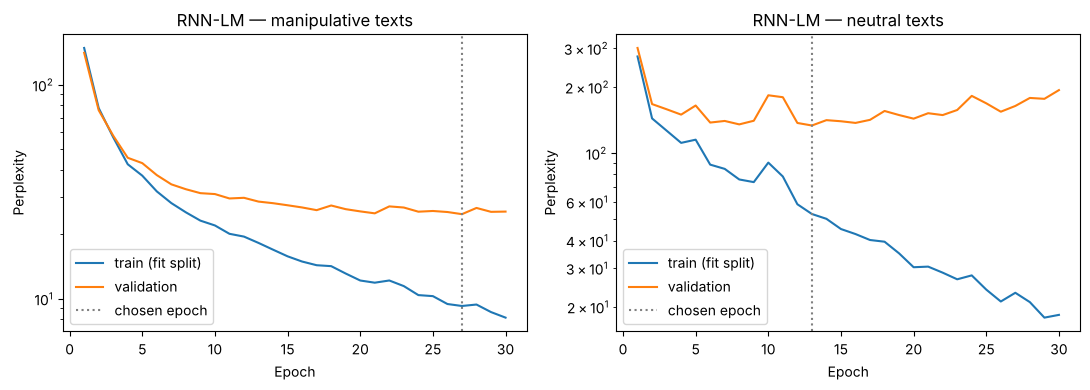

In [14]:
# 5E.1 Choose the number of epochs on validation perplexity, then retrain on the full training split

LM_EPOCHS, LM_LR = 30, 0.5
rnn_lms_by_seed, lm_curves, lm_best_epoch = {seed: {} for seed in SEEDS}, {}, {}
for c, name in [(1, "manipulative"), (0, "neutral")]:
    selection = RNNLanguageModel(seed=SEEDS[0]).fit(
        [seqs[i] for i in fit_idx if y_all[i] == c], epochs=LM_EPOCHS, lr=LM_LR,
        val_sequences=[seqs[i] for i in val_idx if y_all[i] == c])
    lm_curves[name] = pd.DataFrame(selection.history)
    lm_best_epoch[name] = int(lm_curves[name].loc[lm_curves[name]["validation perplexity"].idxmin(), "epoch"])
    for seed in SEEDS:
        rnn_lms_by_seed[seed][c] = RNNLanguageModel(seed=seed).fit(
            [seqs[i] for i in train_idx if y_all[i] == c], epochs=lm_best_epoch[name], lr=LM_LR)
    print(f"{name}: best epoch {lm_best_epoch[name]}, "
          f"validation perplexity {lm_curves[name]['validation perplexity'].min():.1f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (name, curve) in zip(axes, lm_curves.items()):
    ax.plot(curve["epoch"], curve["train perplexity"], label="train (fit split)")
    ax.plot(curve["epoch"], curve["validation perplexity"], label="validation")
    ax.axvline(lm_best_epoch[name], color="grey", linestyle=":", label="chosen epoch")
    ax.set_title(f"RNN-LM — {name} texts"); ax.set_xlabel("Epoch"); ax.set_ylabel("Perplexity"); ax.set_yscale("log")
    ax.legend()
plt.tight_layout()
plt.show()

rnn_lms = rnn_lms_by_seed[SEEDS[0]]     # seed-0 models for the perplexity table and the samples

In [15]:
# 5E.2 Test perplexity: n-gram LMs vs. the RNN-LM (same vocabulary, same training texts)

def class_lms(make_lm):
    return {c: make_lm().fit([seqs[i] for i in train_idx if y_all[i] == c]) for c in (0, 1)}

test_by_class = {c: [seqs[i] for i in test_idx if y_all[i] == c] for c in (0, 1)}
lm_families = {
    "unigram": class_lms(lambda: NGramLM(1, best_by_n[1]["delta"], False)),
    "bigram": class_lms(lambda: NGramLM(2, best_by_n[2]["delta"], best_by_n[2]["backoff"])),
    "trigram": class_lms(lambda: NGramLM(3, best_by_n[3]["delta"], best_by_n[3]["backoff"])),
    "4-gram": class_lms(lambda: NGramLM(4, best_by_n[4]["delta"], best_by_n[4]["backoff"])),
    "RNN-LM": rnn_lms,
}
ppl_rows = []
for name, lms in lm_families.items():
    ppl_rows.append({
        "LM": name,
        "manipulative LM → manipulative test texts": lms[1].perplexity(test_by_class[1]),
        "neutral LM → neutral test texts": lms[0].perplexity(test_by_class[0]),
        "manipulative LM → neutral test texts": lms[1].perplexity(test_by_class[0]),
        "neutral LM → manipulative test texts": lms[0].perplexity(test_by_class[1]),
    })
perplexity_table = pd.DataFrame(ppl_rows)
display(perplexity_table.style.format({c: "{:.1f}" for c in perplexity_table.columns if c != "LM"}))

,LM,manipulative LM → manipulative test texts,neutral LM → neutral test texts,manipulative LM → neutral test texts,neutral LM → manipulative test texts
0,unigram,92.6,89.8,176.6,523.7
1,bigram,29.2,101.1,343.5,1174.1
2,trigram,30.6,129.8,404.0,1221.4
3,4-gram,35.5,144.3,439.3,1258.9
4,RNN-LM,20.3,67.3,241.1,615.3


In [16]:
# 5E.3 Classifying with class-conditional RNN-LMs (Bayes' rule, as in 5A.3)

rnn_priors = {c: np.log(np.mean(y_train == c)) for c in (0, 1)}

def rnn_lm_scores(lms, sequences):
    return (lms[1].sequence_logprobs(sequences) + rnn_priors[1]) - (lms[0].sequence_logprobs(sequences) + rnn_priors[0])

rnn_lm_results = pd.DataFrame([{"seed": seed, **binary_metrics(y_test, (rnn_lm_scores(lms, S(test_idx)) > 0).astype(int))}
                               for seed, lms in rnn_lms_by_seed.items()])
rnn_lm_summary = rnn_lm_results.drop(columns="seed").agg(["mean", "std"])
display(rnn_lm_results.style.format({c: "{:.3f}" for c in ["Accuracy", "Precision", "Recall", "F1"]}).hide(axis="index"))
display(rnn_lm_summary.style.format("{:.3f}"))

seed,Accuracy,Precision,Recall,F1
0,0.955,0.965,0.945,0.955
1,0.960,0.970,0.949,0.959
2,0.960,0.962,0.958,0.960


,Accuracy,Precision,Recall,F1
mean,0.958,0.966,0.951,0.958
std,0.002,0.004,0.006,0.003


In [17]:
# 5E.4 Generating roll-outs from the RNN-LMs

rng_gen = np.random.RandomState(0)
for c, name in [(1, "manipulative"), (0, "neutral")]:
    print(f"RNN-LM trained on {name} texts:")
    for _ in range(6):
        print("   ", rnn_lms[c].sample(rng_gen))
    print()

RNN-LM trained on manipulative texts:
    low stock improve
    hurry only <num> left in stock
    limited time sale
    <unk> <unk> miss out
    your order is reserved for <num> <num> minutes
    hurry only a few left

RNN-LM trained on neutral texts:
    made rare on your text close in the <unk> on the best a charged get the information your <unk> again and social and and be
    <unk>
    new a been
    simons <unk> soft <unk> wigs <unk> with our safety
    <unk>
    absolutely <unk> from now



**Reading 5A.3, 5B and 5E.**

- **A unigram LM, i.e. Naive Bayes, is a strong baseline.** With 0.949 test F1 it is better than every model from Experiments 1–4 (best: Word2Vec + logistic regression, 0.940). Bigram (0.924) and trigram (0.903) LM classifiers are worse, because their counts are too sparse.
- **The RNN-LM has the lowest perplexity on both classes.** It reaches 20.3 on manipulative test texts (best $n$-gram: bigram, 29.2) and 67.3 on neutral texts (best $n$-gram: unigram, 89.8). It uses context like an $n$-gram but has no sparsity problem: similar words have similar embeddings, so a context never seen in training still gets a sensible prediction.
- **The two classes behave differently.** Manipulative texts are templated sentences, where context helps a lot (unigram 92.6 → bigram 29.2). Neutral texts are short, varied UI fragments (median 3 tokens), where a bigram is already *worse* than a unigram. The cross perplexities (241 and 615) show how different the two "languages" are, which is why LM classification works.
- **The neutral texts are also harder to model in training.** The neutral RNN-LM starts to overfit after 13 epochs: validation perplexity rises while training perplexity keeps falling. The manipulative one improves until epoch 27.
- **The RNN-LM classifier is the best model in the project: 0.958 ± 0.003 test F1** (3 seeds). It combines word order with dense, shared representations.
- **Generated text shows the difference.** The trigram LM produces locally plausible fragments that do not form sentences (*"no thanks i story now"*), the lecture's "surprisingly grammatical … but incoherent". The manipulative RNN-LM reproduces whole dark-pattern templates: *"hurry only &lt;num&gt; left in stock"*, *"your order is reserved for &lt;num&gt; &lt;num&gt; minutes"*. Neutral samples contain many `<unk>`s because neutral texts are full of rare product and brand names.
- **Caveat: length.** LM classifiers also predict `</s>`, so they model text length, and neutral texts are much shorter (median 3 vs. 6 tokens). Part of the gain may come from this shortcut (Experiment 1, limitation 1). The external sets (5H) will show whether it transfers to our ads.

## Experiment 5F — The RNN as a text classifier

The LM classifiers above are **generative**: they model each class's texts. The RNN classifier is **discriminative**, like Experiment 4: it reads the text and outputs $P(\text{manipulative} \mid \text{text})$.
It uses the same settings as the Experiment 4 network (SGD, learning rate 0.1, batch 32, 30 epochs, 100 hidden units, GloVe-initialised and fine-tuned embeddings, 3 seeds), but replaces the **average** of word vectors with a **recurrent** encoder.

Two ways to turn the hidden states into one vector are compared:
- **last**: $z = h^{(T)}$. The whole text must be squeezed into the final state, the **bottleneck** the lecture discusses for seq2seq.
- **mean**: $z = \frac1T\sum_t h^{(t)}$. Every time step has a direct path to the output. This is one of the "more direct pass-through connections" the lecture names as a fix for vanishing gradients.

,Accuracy,Precision,Recall,F1,Final train loss,F1 std
Pooling,,,,,,
last,0.938,0.949,0.927,0.938,0.006,0.004
mean,0.948,0.972,0.924,0.947,0.025,0.007


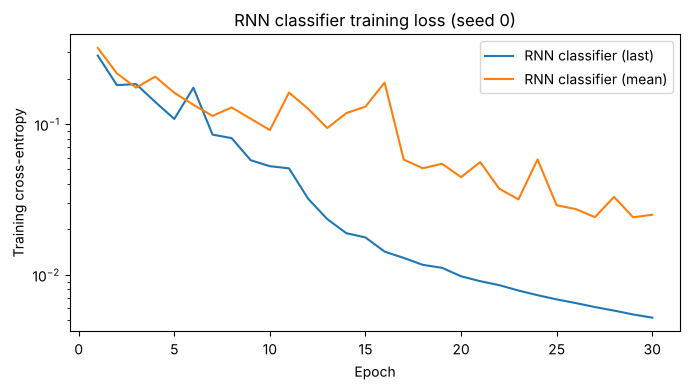

In [18]:
# 5F.1 Train RNN classifiers (3 seeds each, full training split)

rnn_classifiers, rnn_clf_rows = {}, []
for pool in ["last", "mean"]:
    for seed in SEEDS:
        clf = RNNClassifier(hidden=100, pool=pool, seed=seed).fit(S(train_idx), y_train.astype(float))
        rnn_classifiers[(pool, seed)] = clf
        rnn_clf_rows.append({"Pooling": pool, "seed": seed, **binary_metrics(y_test, clf.predict(S(test_idx))),
                             "Final train loss": clf.history[-1]})

rnn_clf_results = pd.DataFrame(rnn_clf_rows)
rnn_clf_summary = rnn_clf_results.groupby("Pooling")[["Accuracy", "Precision", "Recall", "F1", "Final train loss"]].mean()
rnn_clf_summary["F1 std"] = rnn_clf_results.groupby("Pooling")["F1"].std()
display(rnn_clf_summary.style.format("{:.3f}"))

plt.figure(figsize=(7, 4))
for pool in ["last", "mean"]:
    plt.plot(range(1, 31), rnn_classifiers[(pool, 0)].history, label=f"RNN classifier ({pool})")
plt.xlabel("Epoch"); plt.ylabel("Training cross-entropy"); plt.yscale("log")
plt.title("RNN classifier training loss (seed 0)")
plt.legend(); plt.tight_layout(); plt.show()

### 5F.2 Does word order matter?

To test whether the models use word order, we **shuffle the words inside every test text** and predict again.
Bag-of-words models (TF-IDF, the averaged-vector networks of Experiments 3–4, and the unigram LM) are unchanged by construction. Models that read the words in sequence can change their predictions.

In [19]:
# 5F.2 Word-order test

rng_shuffle = np.random.RandomState(0)
shuffled_test = [list(rng_shuffle.permutation(s)) for s in S(test_idx)]

def lm_clf_predict(lms, priors, sequences):
    return (lm_classifier_scores(lms, priors, sequences) > 0).astype(int)

order_models = {
    "unigram LM (= Naive Bayes)": lambda seqs_: lm_clf_predict(*ngram_classifiers["unigram LM (= Naive Bayes)"], seqs_),
    "bigram LM": lambda seqs_: lm_clf_predict(*ngram_classifiers["bigram LM"], seqs_),
    "trigram LM": lambda seqs_: lm_clf_predict(*ngram_classifiers["trigram LM"], seqs_),
    "RNN-LM classifier, seed 0": lambda seqs_: (rnn_lm_scores(rnn_lms, seqs_) > 0).astype(int),
    "RNN classifier (last), seed 0": rnn_classifiers[("last", 0)].predict,
    "RNN classifier (mean), seed 0": rnn_classifiers[("mean", 0)].predict,
}
order_rows = []
for name, predict in order_models.items():
    original, shuffled = predict(S(test_idx)), predict(shuffled_test)
    order_rows.append({"Model": name, "Test F1 — original order": f1_score(y_test, original),
                       "Test F1 — words shuffled": f1_score(y_test, shuffled),
                       "Predictions changed": np.mean(original != shuffled)})
word_order = pd.DataFrame(order_rows)
display(word_order.style.format({"Test F1 — original order": "{:.3f}", "Test F1 — words shuffled": "{:.3f}",
                                 "Predictions changed": "{:.1%}"}))

,Model,Test F1 — original order,Test F1 — words shuffled,Predictions changed
0,unigram LM (= Naive Bayes),0.949,0.949,0.0%
1,bigram LM,0.924,0.765,23.0%
2,trigram LM,0.903,0.744,24.5%
3,"RNN-LM classifier, seed 0",0.955,0.902,7.0%
4,"RNN classifier (last), seed 0",0.938,0.923,7.9%
5,"RNN classifier (mean), seed 0",0.946,0.928,3.8%


**Reading 5F.**

- **Reading in order helps a little.** With the same optimizer settings and initial GloVe embeddings as the Experiment 4 network (averaged vectors, fine-tuned: 0.935), the RNN classifier reaches 0.938 ± 0.004 with the last state and **0.947 ± 0.007 with mean pooling**.
- **Mean pooling beats the last state.** Squeezing the whole text into $h^{(T)}$ is a bottleneck. Mean pooling gives every word a direct path to the output (see also 5G.2 and 5G.4).
- **How much do the models rely on word order?** The bigram and trigram LM classifiers depend on it most: shuffling the words changes 23–25% of their predictions and costs about 0.16 F1. Part of that drop is sparsity, because shuffled word pairs are mostly unseen. The RNN-LM classifier changes 7% of its predictions (0.955 → 0.902). The RNN classifiers change only 4–8% and lose about 0.02 F1. So the discriminative RNN mostly decides from *which* words occur, which is plausible for templated dark patterns where cue words (*left*, *viewing*, *no thanks*) are enough.

## Experiment 5G — Vanishing and exploding gradients

By the chain rule, the gradient that reaches an early hidden state is a **product of Jacobians**:
$$\frac{\partial J^{(T)}}{\partial h^{(1)}} = \frac{\partial h^{(2)}}{\partial h^{(1)}}\cdots\frac{\partial h^{(T)}}{\partial h^{(T-1)}}\,\frac{\partial J^{(T)}}{\partial h^{(T)}}, \qquad
\frac{\partial h^{(t)}}{\partial h^{(t-1)}} = \operatorname{diag}\!\big(1-(h^{(t)})^2\big)\,W_h .$$
If these factors are small, the gradient from far away **vanishes**. If they are large, it **explodes**. Four checks:

1. The size of the Jacobian product for different scales of $W_h$ (the lecture's argument, measured directly).
2. How much gradient actually reaches each word in our trained classifiers.
3. Exploding gradients during training, and how **gradient clipping** handles them.
4. A long-distance dependency test: can the classifier still recognise a manipulative text when neutral words follow it?

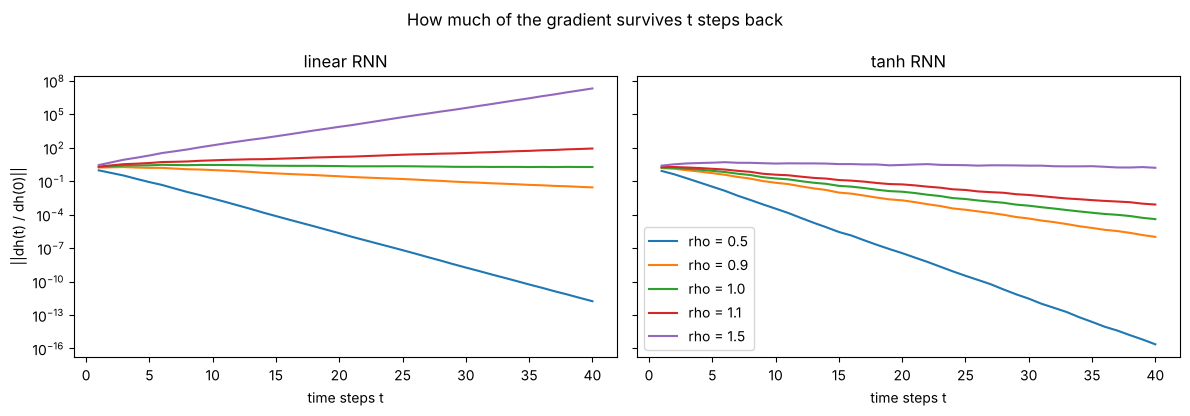

In [20]:
# 5G.1 Norm of the Jacobian product ||dh(t)/dh(0)|| for W_h with spectral radius rho

def jacobian_norms(rho, activation, steps=40, hidden=100, seed=0):
    rng = np.random.RandomState(seed)
    W = rng.randn(hidden, hidden)
    W *= rho / np.max(np.abs(np.linalg.eigvals(W)))                  # set the largest |eigenvalue| to rho
    W_e = rng.randn(hidden, EMB_DIM) * np.sqrt(1.0 / EMB_DIM)
    inputs = E_lm_init[rng.choice(np.arange(4, V), steps)]         # real GloVe word vectors as inputs
    h, J, norms = np.zeros(hidden), np.eye(hidden), []
    for t in range(steps):
        a = W @ h + W_e @ inputs[t]
        h = np.tanh(a) if activation == "tanh" else a
        local = (1 - h ** 2) if activation == "tanh" else np.ones(hidden)
        J = (local[:, None] * W) @ J                               # chain rule: one more factor dh(t)/dh(t-1)
        norms.append(np.linalg.norm(J, 2))
    return np.array(norms)

rhos = [0.5, 0.9, 1.0, 1.1, 1.5]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, activation in zip(axes, ["linear", "tanh"]):
    for rho in rhos:
        ax.plot(range(1, 41), jacobian_norms(rho, activation), label=f"rho = {rho}")
    ax.set_yscale("log"); ax.set_xlabel("time steps t"); ax.set_title(f"{activation} RNN")
axes[0].set_ylabel("||dh(t) / dh(0)||")
axes[1].legend()
plt.suptitle("How much of the gradient survives t steps back")
plt.tight_layout(); plt.show()

jac_table = pd.DataFrame({f"rho = {rho}": [jacobian_norms(rho, act)[k - 1] for act in ["linear", "tanh"] for k in (10, 40)]
                          for rho in rhos},
                         index=pd.MultiIndex.from_product([["linear", "tanh"], ["t = 10", "t = 40"]]))
display(jac_table.style.format("{:.1e}"))

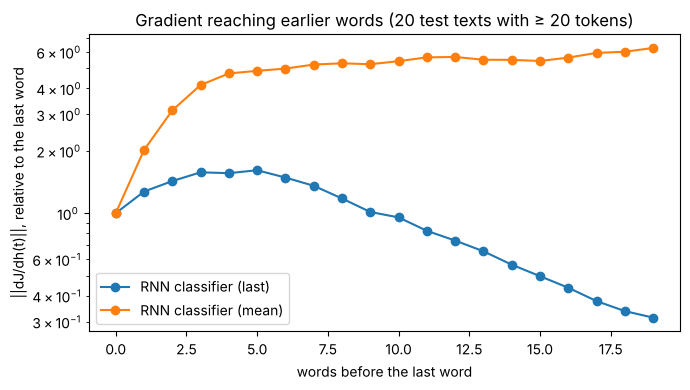

{'last': '3.1e-01 of the last-word gradient reaches 19 words back', 'mean': '6.3e+00 of the last-word gradient reaches 19 words back'}


In [21]:
# 5G.2 Gradient reaching each word in the trained classifiers (test texts with at least 20 tokens)

long_ids = [i for i in test_idx if len(seqs[i]) >= 20]
long_test = S(long_ids)
X_long, M_long, _ = batchify(long_test)
lengths = M_long.sum(axis=1).astype(int)
K = 20
grad_profile = {}
for pool in ["last", "mean"]:
    clf = rnn_classifiers[(pool, 0)]
    clf.loss_and_grads(X_long, M_long, y_all[long_ids].astype(float), trace=True)
    dh = clf.rnn.trace["dh_norm"]
    # ||dJ/dh(t)|| for the last K words, aligned by distance from the last word, relative to the last word
    profile = np.array([[dh[i, lengths[i] - 1 - k] / dh[i, lengths[i] - 1] for k in range(K)] for i in range(len(long_test))])
    grad_profile[pool] = np.exp(np.log(profile + 1e-30).mean(axis=0))     # geometric mean over texts

plt.figure(figsize=(7, 4))
for pool, profile in grad_profile.items():
    plt.plot(range(K), profile, marker="o", label=f"RNN classifier ({pool})")
plt.yscale("log"); plt.xlabel("words before the last word"); plt.ylabel("||dJ/dh(t)||, relative to the last word")
plt.title(f"Gradient reaching earlier words ({len(long_test)} test texts with ≥ 20 tokens)")
plt.legend(); plt.tight_layout(); plt.show()
print({pool: f"{profile[K - 1]:.1e} of the last-word gradient reaches 19 words back" for pool, profile in grad_profile.items()})

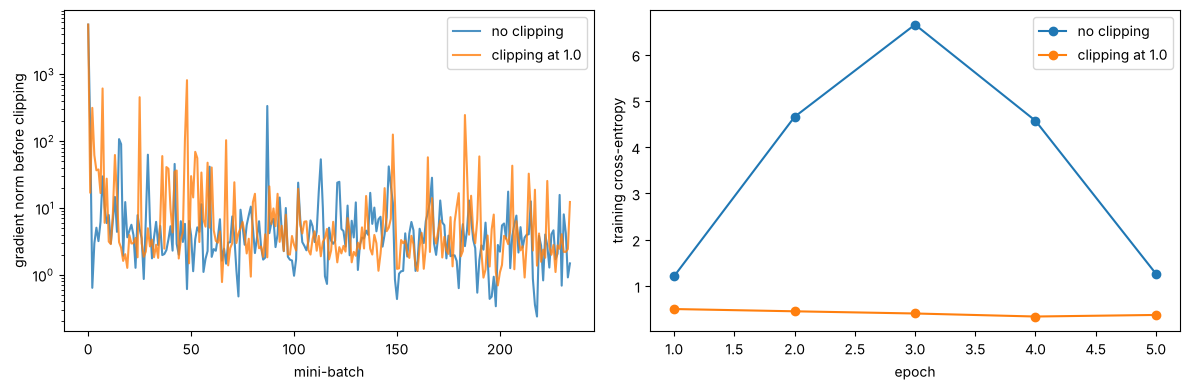

,Run,median gradient norm,max gradient norm,final training loss,validation F1
0,no clipping,3.7,5.6e+03,1.263,0.762
1,clipping at 1.0,3.4,5.6e+03,0.372,0.821


In [22]:
# 5G.3 Exploding gradients and gradient clipping
# Recurrent weights 3x larger than the default initialisation and a large learning rate (1.0)

explode_runs = {}
for clip in [None, 1.0]:
    clf = RNNClassifier(hidden=100, pool="last", seed=0, w_h_scale=3.0)
    with np.errstate(over="ignore", invalid="ignore"):
        clf.fit(S(fit_idx), y_all[fit_idx].astype(float), epochs=5, lr=1.0, clip=clip, log_grad_norms=True)
    explode_runs["no clipping" if clip is None else f"clipping at {clip}"] = clf

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, clf in explode_runs.items():
    axes[0].plot(clf.grad_norms, label=name, alpha=0.8)
    axes[1].plot(range(1, 6), clf.history, marker="o", label=name)
axes[0].set_yscale("log"); axes[0].set_xlabel("mini-batch"); axes[0].set_ylabel("gradient norm before clipping")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("training cross-entropy")
axes[0].legend(); axes[1].legend()
plt.tight_layout(); plt.show()

display(pd.DataFrame([{
    "Run": name,
    "median gradient norm": np.median(clf.grad_norms),
    "max gradient norm": np.max(clf.grad_norms),
    "final training loss": clf.history[-1],
    "validation F1": f1_score(y_all[val_idx], clf.predict(S(val_idx))),
} for name, clf in explode_runs.items()]).style.format({"median gradient norm": "{:.2g}", "max gradient norm": "{:.2g}",
                                                         "final training loss": "{:.3f}", "validation F1": "{:.3f}"}))

In [23]:
# 5G.4 Long-distance dependency: append k neutral filler words after every manipulative test text

rng_filler = np.random.RandomState(0)
filler_pool = [w for i in rng_filler.permutation(train_idx[y_train == 0]) for w in seqs[i] if w != stoi[UNK]]
manip_test = [seqs[i] for i in test_idx if y_all[i] == 1]

probe_rows = []
for k in [0, 5, 10, 20, 40]:
    starts = rng_filler.randint(0, len(filler_pool) - k - 1, size=len(manip_test))
    padded = [s + filler_pool[a:a + k] for s, a in zip(manip_test, starts)]
    row = {"neutral words appended": k}
    for pool in ["last", "mean"]:
        row[f"RNN classifier ({pool}): still detected"] = np.mean([rnn_classifiers[(pool, seed)].predict(padded).mean()
                                                                   for seed in SEEDS])
    probe_rows.append(row)
probe = pd.DataFrame(probe_rows)
display(probe.style.format({c: "{:.1%}" for c in probe.columns if c != "neutral words appended"}).hide(axis="index"))

neutral words appended,RNN classifier (last): still detected,RNN classifier (mean): still detected
0,92.7%,92.4%
5,72.9%,93.1%
10,41.0%,91.1%
20,19.8%,77.5%
40,16.7%,35.3%


**Reading 5G.**

- **5G.1 — vanishing vs. exploding.** In a linear RNN the gradient scales like $\rho^t$: after 40 steps only $1.7 \times 10^{-12}$ survives with $\rho = 0.5$, while it grows to $2 \times 10^{7}$ with $\rho = 1.5$. tanh multiplies by its derivative ($\le 1$) at every step. Even with $\rho = 1$, only $4 \times 10^{-5}$ of the gradient survives 40 steps, and saturation keeps the $\rho = 1.5$ network near 1. For a tanh RNN, **vanishing** is the usual problem.
- **5G.2 — in our trained classifiers.** For the 20 test texts with at least 20 tokens, the last-state classifier passes about 0.31 of the last word's gradient back to the word 19 positions earlier. The gradient shrinks with distance even on these short texts. With mean pooling, earlier words receive *more* gradient than the last word (6.3×), because each hidden state reaches the output directly *and* through every later state.
- **5G.3 — exploding gradients and clipping.** With recurrent weights 3× larger than the default and learning rate 1.0, single mini-batches have gradient norms up to $5.6 \times 10^{3}$, against a median of about 3.5. Without clipping, the training loss jumps to 6.7 in epoch 3 and is still 1.263 after 5 epochs (validation F1 0.762). With clipping (same direction, smaller step), it ends at 0.372 and 0.821. In the lecture's words, clipping is easy and important.
- **5G.4 — the practical consequence.** This is our version of the lecture's *"she finally printed her ___"* example. When neutral words follow a manipulative text, the last-state RNN quickly **forgets** the cue: detection drops from 92.7% to 41% after 10 extra words and to 17% after 40. Mean pooling keeps 91% after 10 words and 78% after 20. It falls only at 40 (35%), because the cue is **diluted** by averaging rather than forgotten. Model weights are mostly updated "with respect to near effects", which is why the lecture points to LSTMs and to more direct connections (attention, residual connections) as the fix.

## Experiment 5H — Comparison with Experiments 1–4

All models are evaluated on the same held-out test set. The external columns appear when the original project dataset is in `data/`.

In [24]:
# 5H.1 Overall comparison

def predictions(model_name, sequences):
    if model_name in ngram_classifiers:
        return lm_clf_predict(*ngram_classifiers[model_name], sequences)
    # for the external sets the 3 seeds are combined (mean score / majority vote); the test F1 is the mean over seeds
    if model_name == "RNN-LM classifier":
        return (np.mean([rnn_lm_scores(lms, sequences) for lms in rnn_lms_by_seed.values()], axis=0) > 0).astype(int)
    pool = "last" if "(last)" in model_name else "mean"
    return (np.mean([rnn_classifiers[(pool, s)].predict(sequences) for s in SEEDS], axis=0) > 0.5).astype(int)

exp5_models = ["unigram LM (= Naive Bayes)", "bigram LM", "trigram LM", "RNN-LM classifier",
               "RNN classifier (last)", "RNN classifier (mean)"]
hard_neg = (external_synthetic_df["source"] == "synthetic_hard_negative").to_numpy()
exp5_rows = []
for name in exp5_models:
    if name.startswith("RNN classifier"):
        test_f1 = rnn_clf_summary.loc["last" if "(last)" in name else "mean", "F1"]
    elif name == "RNN-LM classifier":
        test_f1 = rnn_lm_summary.loc["mean", "F1"]
    else:
        test_f1 = f1_score(y_test, predictions(name, S(test_idx)))
    row = {"Model": f"Exp. 5 — {name}", "Test F1": test_f1}
    if HAS_EXTERNAL:
        synth_pred = predictions(name, synth_seqs)
        y_synth = external_synthetic_df["manipulative"].astype(int).to_numpy()
        row.update({"Real ads F1": f1_score(real_df["manipulative"].astype(int), predictions(name, real_seqs)),
                    "Synthetic F1": f1_score(y_synth, synth_pred),
                    "Hard-negative accuracy": accuracy_score(y_synth[hard_neg], synth_pred[hard_neg])})
    exp5_rows.append(row)
exp5_comparison = pd.DataFrame(exp5_rows)

previous = load_table("exp4_overall_comparison")
previous["Model"] = ["Exp. 1 — " + m if m.startswith("TF-IDF") else
                     "Exp. 3 — " + m if "logistic regression" in m else "Exp. 4 — " + m for m in previous["Model"]]
overall = pd.concat([previous, exp5_comparison], ignore_index=True)
if not HAS_EXTERNAL:
    overall = overall[["Model", "Test F1"]]
display(overall.style.format({c: "{:.3f}" for c in overall.columns if c != "Model"}, na_rep="—")
        .highlight_max(subset=["Test F1"], color="#d4edda"))

,Model,Test F1
0,Exp. 1 — TF-IDF + logistic regression,0.932
1,Exp. 3 — Word2Vec — project corpus + logistic regression,0.940
2,Exp. 3 — Pretrained GloVe + logistic regression,0.904
3,Exp. 4 — NN (ReLU) — frozen GloVe,0.928
4,Exp. 4 — NN (ReLU) — fine-tuned embeddings,0.935
5,"Exp. 4 — NN (linear, no non-linearity) — frozen GloVe",0.901
6,Exp. 5 — unigram LM (= Naive Bayes),0.949
7,Exp. 5 — bigram LM,0.924
8,Exp. 5 — trigram LM,0.903
9,Exp. 5 — RNN-LM classifier,0.958


In [25]:
# 5H.2 Perplexity as a measure of domain shift (needs the original project dataset)
# How "surprising" are our own ads to language models trained on website dark patterns?

if HAS_EXTERNAL:
    ext_sets = {"dark-patterns test set": S(test_idx), "our real ads": real_seqs, "our synthetic texts": synth_seqs}
    display(pd.DataFrame([{"LM": f"{name} ({cls})", **{set_name: lms[c].perplexity(set_seqs) for set_name, set_seqs in ext_sets.items()}}
                          for name, lms in [("trigram", lm_families["trigram"]), ("RNN-LM", rnn_lms)]
                          for c, cls in [(1, "manipulative"), (0, "neutral")]]).style.format(
        {k: "{:.1f}" for k in ext_sets}))
else:
    print("Original project dataset not found in data/ — external check skipped.")

Original project dataset not found in data/ — external check skipped.


In [26]:
# 5H.3 Save results

save_table(perplexity_table, "exp5_perplexity")
save_table(ngram_grid, "exp5_ngram_validation_grid")
save_table(word_order, "exp5_word_order")
save_table(overall, "exp5_overall_comparison")
print("Saved to results/.")

Saved to results/.


# Experiment 5 — Summary

| Model (same test split) | Test F1 |
|---|---|
| TF-IDF + logistic regression (Exp. 1) | 0.932 |
| Word2Vec + logistic regression (Exp. 3) | 0.940 |
| NN, ReLU, fine-tuned embeddings (Exp. 4) | 0.935 |
| Unigram LM classifier (= Naive Bayes) | 0.949 |
| Bigram LM classifier | 0.924 |
| Trigram LM classifier | 0.903 |
| RNN classifier, last state | 0.938 ± 0.004 |
| RNN classifier, mean of states | 0.947 ± 0.007 |
| **RNN-LM classifier** (class-conditional RNN language models) | **0.958 ± 0.003** |

| Test perplexity (lower is better) | Manipulative texts | Neutral texts |
|---|---|---|
| Best $n$-gram | 29.2 (bigram) | 89.8 (unigram) |
| RNN-LM | **20.3** | **67.3** |

**What the lecture predicts, and what we observed**

1. *$n$-gram LMs suffer from sparsity; smoothing and backoff only partly help.* Half of the test 4-grams never occur in training. Backoff lowers trigram/4-gram perplexity by a third to a half, but the bigram is still the best $n$-gram (5A).
2. *Generated $n$-gram text is grammatical but incoherent.* The RNN-LM reproduces whole dark-pattern templates (5B, 5E.4).
3. *RNNs apply the same weights at every step; BPTT sums the gradient over the steps.* Verified numerically for every parameter (5D).
4. *RNN-LMs beat $n$-gram LMs in perplexity.* Yes, by 25–30% on both classes (5E.2).
5. *Vanishing gradients make long-distance dependencies hard; clipping fixes exploding gradients.* Both are visible on our data (5G). A last-state RNN forgets a manipulative cue after about 10 following words.

**What this means for our research question**
- Treating manipulative and neutral text as two different "languages" and classifying with **class-conditional language models** gives the best in-domain result of the project (RNN-LM: 0.958). Even the simplest version, Naive Bayes, beats all earlier models.
- Word order adds less than expected for the *discriminative* RNN classifier. In this templated domain, *which* words occur carries most of the signal.
- The LM view also offers a way to **measure domain shift**: the perplexity of our own ads under the dark-pattern LMs (5H.2, runs once the original project dataset is in `data/`).

**Limitations.**
- The external sets were not available for this run, so out-of-domain transfer, the main weakness found in Experiments 1–4, is not yet tested for these models.
- LM classifiers also model text length, a known shortcut in this dataset.
- 20% of test tokens are `<unk>`.
- The vanilla RNN is shallow (one layer, 100 units). Hyperparameters were not tuned beyond the $n$-gram settings and the RNN-LM epochs.
- One train/test split, 3 seeds.

**Next steps.** LSTM/GRU cells (the lecture's fix for vanishing gradients) and attention; evaluating all Experiment 5 models on the external sets; a length-controlled comparison of the LM classifiers.